In [181]:
!pip install pyod
!pip install combo

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for combo: filename=combo-0.1.3-py3-none-any.whl size=42939 sha256=ec487df38eba46f4a55804a1073ec2e809143fe0f5ce41b13ed42d8f2bb8a0f8
  Stored in directory: /root/.cache/pip/wheels/11/30/9c/eef59ace09565d3123c0592eb614000da0e02c11541298513a
Successfully built combo


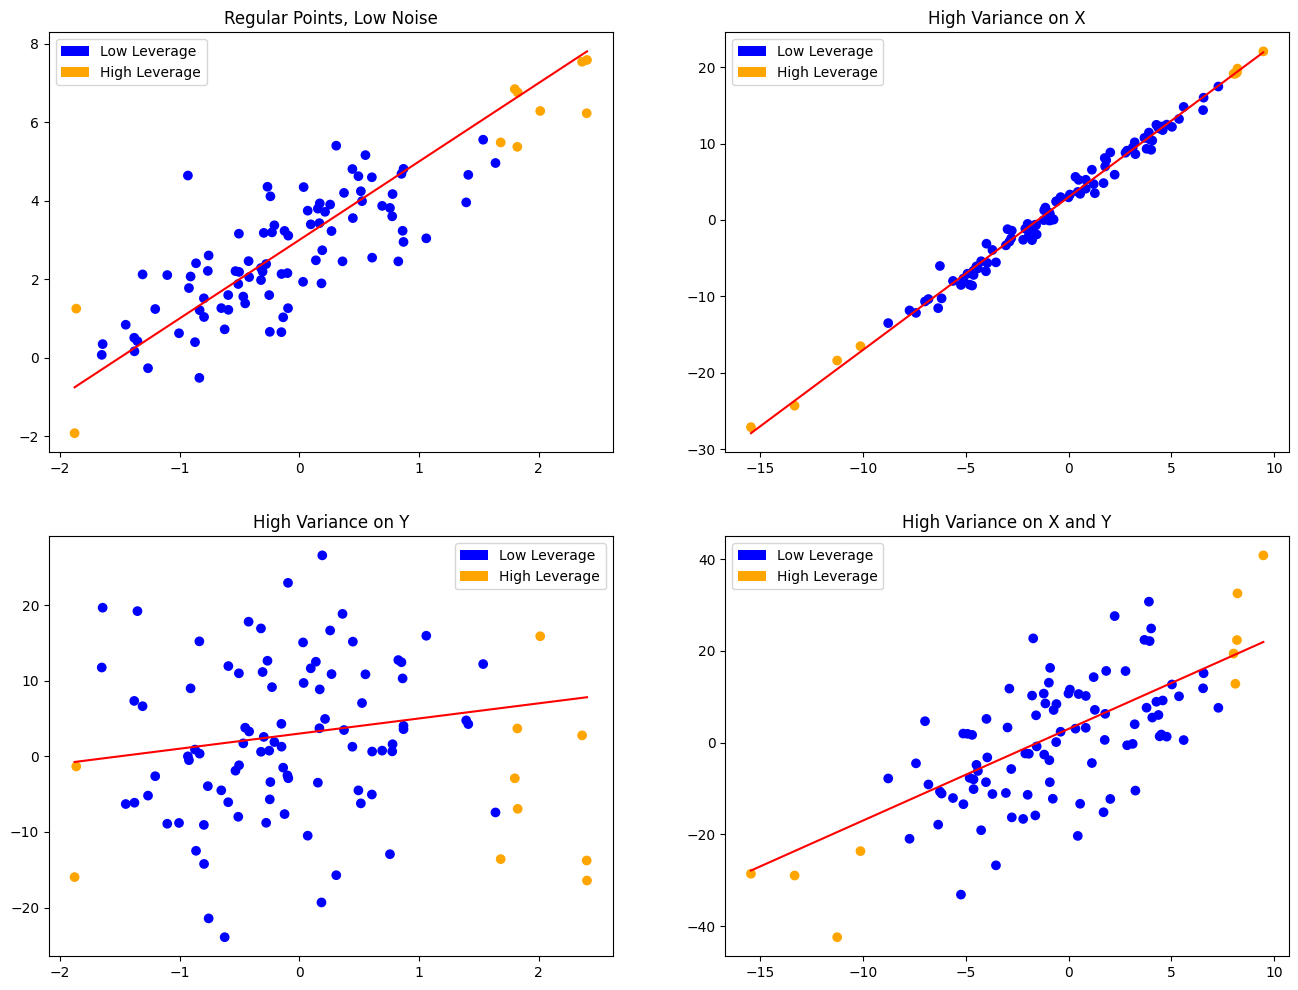

1.9999999999999998
2.0000000000000004


In [ ]:
# Ex. 1 for y = ax + b + e

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

x1 = np.random.normal(loc=0, scale=1, size=100)
x2 = np.random.normal(loc=0, scale=5, size=100)

e1 = np.random.normal(loc=0, scale=1, size=100)
e2 = np.random.normal(loc=0, scale=10, size=100)

a = 2
b = 3

y1 = a * x1 + b + e1   # Regular Points, Low Noise
y2 = a * x2 + b + e1   # High Variance on X
y3 = a * x1 + b + e2   # High Variance on Y
y4 = a * x2 + b + e2   # High Variance on X and Y

p = 2    # i.e.  a, b
n = len(x1)

lev_sc1 = 1/n + ((x1 - np.mean(x1))**2 / np.sum((x1 - np.mean(x1))**2))
lev_sc2 = 1/n + ((x2 - np.mean(x2))**2 / np.sum((x2 - np.mean(x2))**2))

clrs1 = np.where(lev_sc1 <= 2*p/n, 'blue', 'orange')
clrs2 = np.where(lev_sc2 <= 2*p/n, 'blue', 'orange')

lgnd_elms = [
    Patch(facecolor='blue', label='Low Leverage'),
    Patch(facecolor='orange', label='High Leverage')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].scatter(x1, y1, color=clrs1)
axes[0, 0].set_title('Regular Points, Low Noise')
axes[0, 0].legend(handles=lgnd_elms)

axes[0, 1].scatter(x2, y2, color=clrs2)
axes[0, 1].set_title('High Variance on X')
axes[0, 1].legend(handles=lgnd_elms)

axes[1, 0].scatter(x1, y3, color=clrs1)
axes[1, 0].set_title('High Variance on Y')
axes[1, 0].legend(handles=lgnd_elms)

axes[1, 1].scatter(x2, y4, color=clrs2)
axes[1, 1].set_title('High Variance on X and Y')
axes[1, 1].legend(handles=lgnd_elms)

x_line1 = np.linspace(np.min(x1), np.max(x1), 50)
x_line2 = np.linspace(np.min(x2), np.max(x2), 50)

y_line1 = a * x_line1 + b
y_line2 = a * x_line2 + b

axes[0, 0].plot(x_line1, y_line1, color='red')
axes[0, 1].plot(x_line2, y_line2, color='red')
axes[1, 0].plot(x_line1, y_line1, color='red')
axes[1, 1].plot(x_line2, y_line2, color='red')

plt.show()

print(np.sum(lev_sc1))
print(np.sum(lev_sc2))

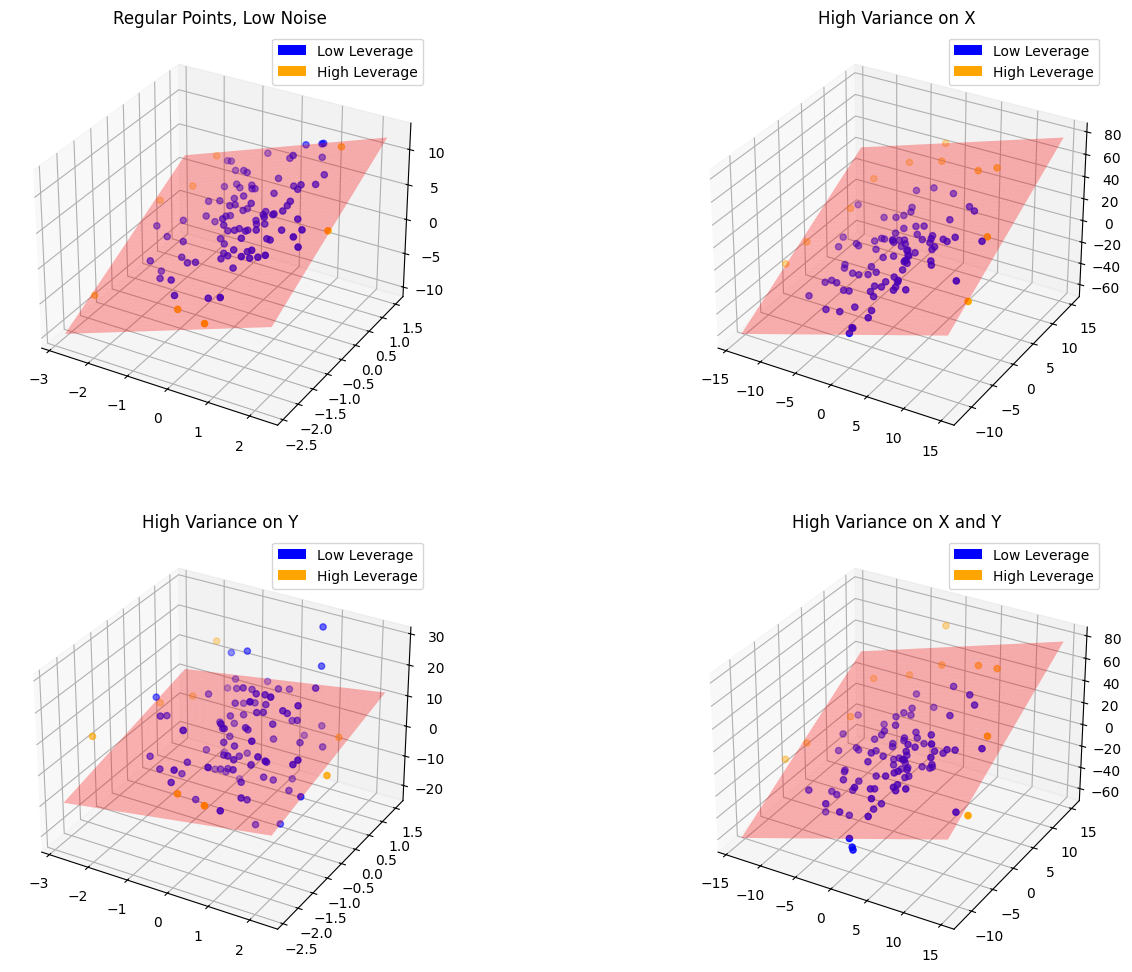

3.0000000000000004
3.0
0.030000000000000006
0.03


In [ ]:
# Ex. 1 for y = ax1 + bx2 + c + e

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

x1_1 = np.random.normal(loc=0, scale=1, size=100)
x1_2 = np.random.normal(loc=0, scale=5, size=100)
x2_1 = np.random.normal(loc=0, scale=1, size=100)
x2_2 = np.random.normal(loc=0, scale=5, size=100)

e1 = np.random.normal(loc=0, scale=1, size=100)
e2 = np.random.normal(loc=0, scale=10, size=100)

a = 2
b = 3
c = 3

y1 = a * x1_1 + b * x2_1 + c + e1   # Regular Points, Low Noise
y2 = a * x1_2 + b * x2_2 + c + e1   # High Variance on X1 and X2
y3 = a * x1_1 + b * x2_1 + c + e2   # High Variance on Y
y4 = a * x1_2 + b * x2_2 + c + e2   # High Variance on X1, X2 and Y

n = len(x1_1)

X1 = np.ones((n, 3))
X1[:, 1] = x1_1
X1[:, 2] = x2_1

X2 = np.ones((n, 3))
X2[:, 1] = x1_2
X2[:, 2] = x2_2

p = 3   # i.e.  a, b, c

LevSc1 = X1 @ np.linalg.inv(X1.T @ X1) @ X1.T
LevSc2 = X2 @ np.linalg.inv(X2.T @ X2) @ X2.T

LevScDiag1 = LevSc1.diagonal()
LevScDiag2 = LevSc2.diagonal()

clrs1 = np.where(LevScDiag1 <= 2*p/n, 'blue', 'orange')

clrs2 = np.where(LevScDiag2 <= 2*p/n, 'blue', 'orange')

lgnd_elms = [
    Patch(facecolor='blue', label='Low Leverage'),
    Patch(facecolor='orange', label='High Leverage')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 12), subplot_kw={"projection": "3d"})

axes[0, 0].scatter(x1_1, x2_1, y1, color=clrs1)
axes[0, 0].set_title('Regular Points, Low Noise')
axes[0, 0].legend(handles=lgnd_elms)

axes[0, 1].scatter(x1_2, x2_2, y2, color=clrs2)
axes[0, 1].set_title('High Variance on X')
axes[0, 1].legend(handles=lgnd_elms)

axes[1, 0].scatter(x1_1, x2_1, y3, color=clrs1)
axes[1, 0].set_title('High Variance on Y')
axes[1, 0].legend(handles=lgnd_elms)

axes[1, 1].scatter(x1_2, x2_2, y4, color=clrs2)
axes[1, 1].set_title('High Variance on X and Y')
axes[1, 1].legend(handles=lgnd_elms)

x1_1_line = np.linspace(np.min(x1_1), np.max(x1_1), 50)
x2_1_line = np.linspace(np.min(x2_1), np.max(x2_1), 50)
x1_2_line = np.linspace(np.min(x1_2), np.max(x1_2), 50)
x2_2_line = np.linspace(np.min(x2_2), np.max(x2_2), 50)

X1_1, X2_1 = np.meshgrid(x1_1_line, x2_1_line)
y_line1 = a * X1_1 + b * X2_1 + c

X1_2, X2_2 = np.meshgrid(x1_2_line, x2_2_line)
y_line2 = a * X1_2 + b * X2_2 + c

axes[0, 0].plot_surface(X1_1, X2_1, y_line1, color='red', alpha=0.3)
axes[0, 1].plot_surface(X1_2, X2_2, y_line2, color='red', alpha=0.3)
axes[1, 0].plot_surface(X1_1, X2_1, y_line1, color='red', alpha=0.3)
axes[1, 1].plot_surface(X1_2, X2_2, y_line2, color='red', alpha=0.3)

plt.show()

print(np.sum(LevScDiag1))
print(np.sum(LevScDiag2))

print(np.mean(LevScDiag1))
print(np.mean(LevScDiag2))

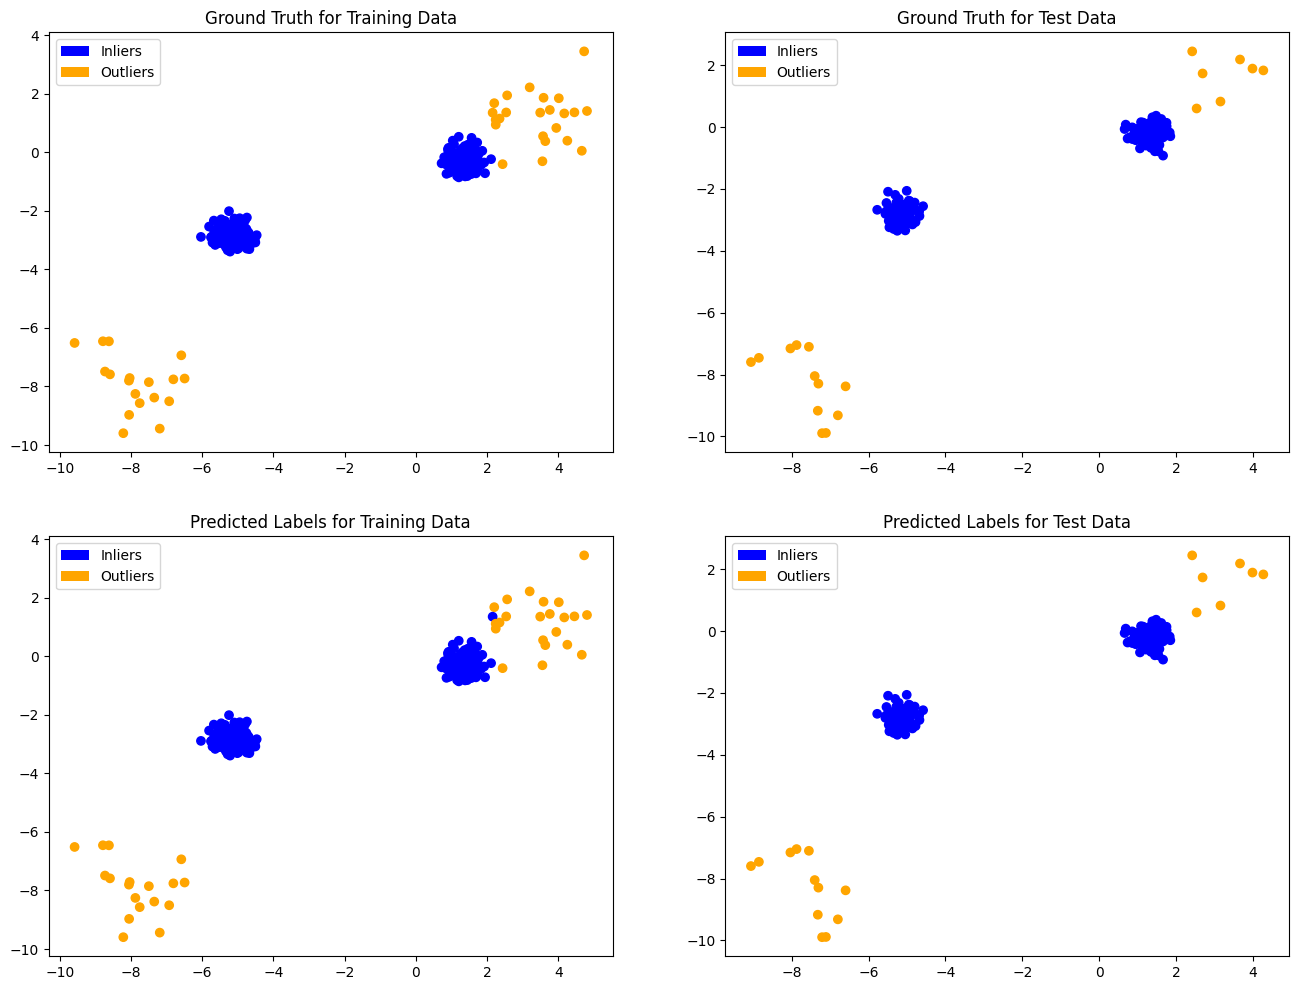

Balanced Accuracy Score on Training Data: 0.9878048780487805

Balanced Accuracy Score on Test Data 1.0









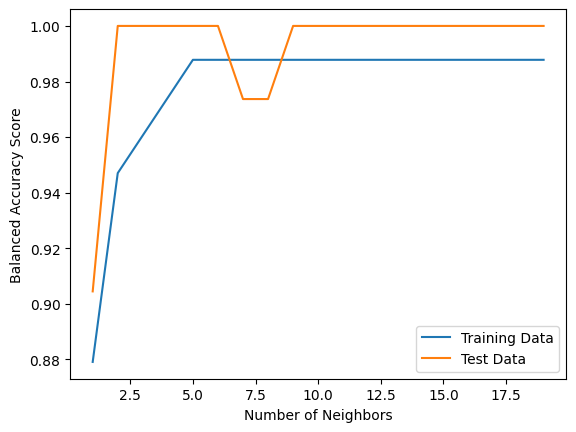

In [153]:
# Ex. 2

from pyod.utils.data import generate_data_clusters
from pyod.models.knn import KNN
from sklearn.metrics import balanced_accuracy_score

X_train, X_test, Y_train, Y_test = generate_data_clusters(
    n_train=400,
    n_test=200,
    n_features=2,
    n_clusters=2,
    contamination=0.1,
    random_state=42
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

lgnd = [
    Patch(facecolor='blue', label='Inliers'),
    Patch(facecolor='orange', label='Outliers')
]

clrs_train = np.where(Y_train == 0, 'blue', 'orange')
clrs_test = np.where(Y_test == 0, 'blue', 'orange')

axes[0, 0].scatter(X_train[:, 0], X_train[:, 1], color=clrs_train)
axes[0, 0].set_title('Ground Truth for Training Data')
axes[0, 0].legend(handles=lgnd)

axes[0, 1].scatter(X_test[:, 0], X_test[:, 1], color=clrs_test)
axes[0, 1].set_title('Ground Truth for Test Data')
axes[0, 1].legend(handles=lgnd)

# === Number of Neighbors for Visualisation ===
k = 5
# =============================================

model = KNN(n_neighbors=k, contamination=0.1)
model.fit(X_train)
Y_train_pred = model.labels_
Y_test_pred = model.predict(X_test)

clrs_pred_train = np.where(Y_train_pred == 0, 'blue', 'orange')
clrs_pred_test = np.where(Y_test_pred == 0, 'blue', 'orange')

axes[1, 0].scatter(X_train[:, 0], X_train[:, 1], color=clrs_pred_train)
axes[1, 0].set_title('Predicted Labels for Training Data')
axes[1, 0].legend(handles=lgnd)

axes[1, 1].scatter(X_test[:, 0], X_test[:, 1], color=clrs_pred_test)
axes[1, 1].set_title('Predicted Labels for Test Data')
axes[1, 1].legend(handles=lgnd)

plt.show()

print("Balanced Accuracy Score on Training Data:", balanced_accuracy_score(Y_train, Y_train_pred))
print("\nBalanced Accuracy Score on Test Data", balanced_accuracy_score(Y_test, Y_test_pred))
print("\n\n\n\n\n\n")

# === Experimental k values ===

train_scores = []
test_scores = []

for k in range(1,20):
    model = KNN(n_neighbors=k, contamination=0.1)
    model.fit(X_train)
    Y_train_pred = model.labels_
    Y_test_pred = model.predict(X_test)
    train_scores.append(balanced_accuracy_score(Y_train, Y_train_pred))
    test_scores.append(balanced_accuracy_score(Y_test, Y_test_pred))

plt.plot(range(1, 20), train_scores, label='Training Data')
plt.plot(range(1, 20), test_scores, label='Test Data')
plt.xlabel('Number of Neighbors')
plt.ylabel('Balanced Accuracy Score')
plt.legend()
plt.show()

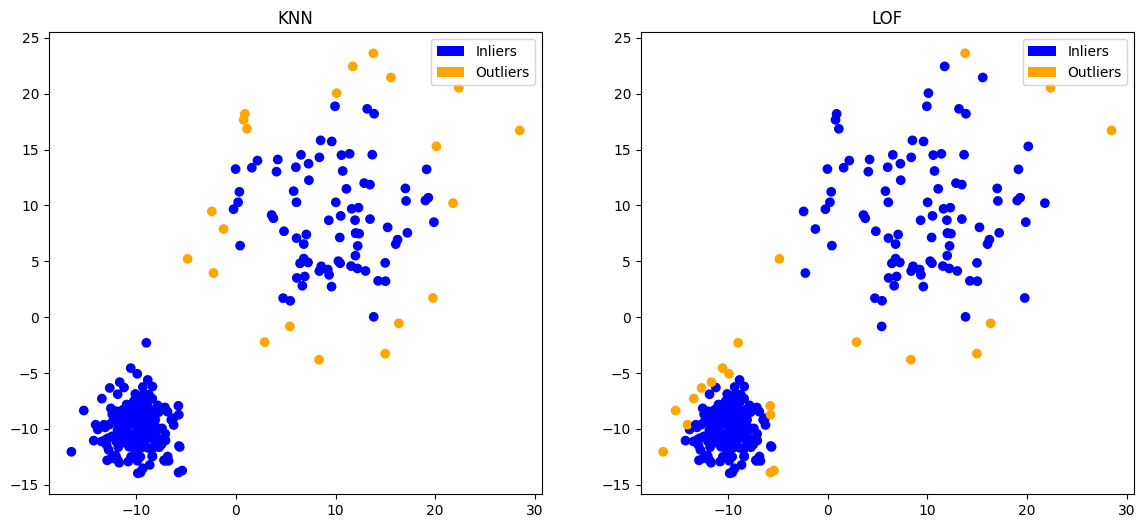



Anomalies in the First Cluster (KNN): 0
Anomalies in the First Cluster (LOF): 13


Anomalies in the Second Cluster (KNN): 21
Anomalies in the Second Cluster (LOF): 8


In [174]:
# Ex. 3

from pyod.models.lof import LOF
from sklearn.datasets import make_blobs

X, Y = make_blobs(
    n_samples=[200,100],
    centers=[[-10, -10], [10, 10]],
    cluster_std=[2, 6],
    random_state=42
)

m_knn = KNN(n_neighbors=20, contamination=0.07)
m_knn.fit(X)
Y_pred_knn = m_knn.labels_

m_lof = LOF(n_neighbors=20, contamination=0.07)
m_lof.fit(X)
Y_pred_lof = m_lof.labels_

clrs_knn = np.where(Y_pred_knn == 0, 'blue', 'orange')
clrs_lof = np.where(Y_pred_lof == 0, 'blue', 'orange')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X[:, 0], X[:, 1], color=clrs_knn)
axes[0].set_title('KNN')
axes[0].legend(handles=lgnd)

axes[1].scatter(X[:, 0], X[:, 1], color=clrs_lof)
axes[1].set_title('LOF')
axes[1].legend(handles=lgnd)

plt.show()

print("\n")
print("Anomalies in the First Cluster (KNN):",np.sum(Y_pred_knn[Y == 0]))
print("Anomalies in the First Cluster (LOF):", np.sum(Y_pred_lof[Y == 0]))
print("\n")
print("Anomalies in the Second Cluster (KNN):", np.sum(Y_pred_knn[Y == 1]))
print("Anomalies in the Second Cluster (LOF):",np.sum(Y_pred_lof[Y == 1]))

In [187]:
# Ex. 4

from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from pyod.utils.utility import standardizer
from pyod.models.combination import average, maximization

data = loadmat('cardio.mat')

X_train, X_test, Y_train, Y_test = train_test_split(
    data['X'],
    data['y'],
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

m1_knn = KNN(n_neighbors=30)
m1_knn.fit(X_train_scaled)
Y_train_pred1 = m1_knn.labels_
Y_test_pred1 = m1_knn.predict(X_test_scaled)

m2_knn = KNN(n_neighbors=40)
m2_knn.fit(X_train_scaled)
Y_train_pred2 = m2_knn.labels_
Y_test_pred2 = m2_knn.predict(X_test_scaled)

m3_knn = KNN(n_neighbors=50)
m3_knn.fit(X_train_scaled)
Y_train_pred3 = m3_knn.labels_
Y_test_pred3 = m3_knn.predict(X_test_scaled)

m4_knn = KNN(n_neighbors=60)
m4_knn.fit(X_train_scaled)
Y_train_pred4 = m4_knn.labels_
Y_test_pred4 = m4_knn.predict(X_test_scaled)

m5_knn = KNN(n_neighbors=70)
m5_knn.fit(X_train_scaled)
Y_train_pred5 = m5_knn.labels_
Y_test_pred5 = m5_knn.predict(X_test_scaled)

m6_knn = KNN(n_neighbors=80)
m6_knn.fit(X_train_scaled)
Y_train_pred6 = m6_knn.labels_
Y_test_pred6 = m6_knn.predict(X_test_scaled)

m7_knn = KNN(n_neighbors=90)
m7_knn.fit(X_train_scaled)
Y_train_pred7 = m7_knn.labels_
Y_test_pred7 = m7_knn.predict(X_test_scaled)

m8_knn = KNN(n_neighbors=100)
m8_knn.fit(X_train_scaled)
Y_train_pred8 = m8_knn.labels_
Y_test_pred8 = m8_knn.predict(X_test_scaled)

m9_knn = KNN(n_neighbors=110)
m9_knn.fit(X_train_scaled)
Y_train_pred9 = m9_knn.labels_
Y_test_pred9 = m9_knn.predict(X_test_scaled)

m10_knn = KNN(n_neighbors=120)
m10_knn.fit(X_train_scaled)
Y_train_pred10 = m10_knn.labels_
Y_test_pred10 = m10_knn.predict(X_test_scaled)

ba_train_m1 = balanced_accuracy_score(Y_train, Y_train_pred1)
ba_train_m2 = balanced_accuracy_score(Y_train, Y_train_pred2)
ba_train_m3 = balanced_accuracy_score(Y_train, Y_train_pred3)
ba_train_m4 = balanced_accuracy_score(Y_train, Y_train_pred4)
ba_train_m5 = balanced_accuracy_score(Y_train, Y_train_pred5)
ba_train_m6 = balanced_accuracy_score(Y_train, Y_train_pred6)
ba_train_m7 = balanced_accuracy_score(Y_train, Y_train_pred7)
ba_train_m8 = balanced_accuracy_score(Y_train, Y_train_pred8)
ba_train_m9 = balanced_accuracy_score(Y_train, Y_train_pred9)
ba_train_m10 = balanced_accuracy_score(Y_train, Y_train_pred10)

ba_test_m1 = balanced_accuracy_score(Y_test, Y_test_pred1)
ba_test_m2 = balanced_accuracy_score(Y_test, Y_test_pred2)
ba_test_m3 = balanced_accuracy_score(Y_test, Y_test_pred3)
ba_test_m4 = balanced_accuracy_score(Y_test, Y_test_pred4)
ba_test_m5 = balanced_accuracy_score(Y_test, Y_test_pred5)
ba_test_m6 = balanced_accuracy_score(Y_test, Y_test_pred6)
ba_test_m7 = balanced_accuracy_score(Y_test, Y_test_pred7)
ba_test_m8 = balanced_accuracy_score(Y_test, Y_test_pred8)
ba_test_m9 = balanced_accuracy_score(Y_test, Y_test_pred9)
ba_test_m10 = balanced_accuracy_score(Y_test, Y_test_pred10)

dec_scr_m1 = m1_knn.decision_scores_
dec_scr_m2 = m2_knn.decision_scores_
dec_scr_m3 = m3_knn.decision_scores_
dec_scr_m4 = m4_knn.decision_scores_
dec_scr_m5 = m5_knn.decision_scores_
dec_scr_m6 = m6_knn.decision_scores_
dec_scr_m7 = m7_knn.decision_scores_
dec_scr_m8 = m8_knn.decision_scores_
dec_scr_m9 = m9_knn.decision_scores_
dec_scr_m10 = m10_knn.decision_scores_

dec_fct_m1 = m1_knn.decision_function(X_test_scaled)
dec_fct_m2 = m2_knn.decision_function(X_test_scaled)
dec_fct_m3 = m3_knn.decision_function(X_test_scaled)
dec_fct_m4 = m4_knn.decision_function(X_test_scaled)
dec_fct_m5 = m5_knn.decision_function(X_test_scaled)
dec_fct_m6 = m6_knn.decision_function(X_test_scaled)
dec_fct_m7 = m7_knn.decision_function(X_test_scaled)
dec_fct_m8 = m8_knn.decision_function(X_test_scaled)
dec_fct_m9 = m9_knn.decision_function(X_test_scaled)
dec_fct_m10 = m10_knn.decision_function(X_test_scaled)

train_scores = np.column_stack((
    dec_scr_m1,
    dec_scr_m2,
    dec_scr_m3,
    dec_scr_m4,
    dec_scr_m5,
    dec_scr_m6,
    dec_scr_m7,
    dec_scr_m8,
    dec_scr_m9,
    dec_scr_m10
))

test_scores = np.column_stack((
    dec_fct_m1,
    dec_fct_m2,
    dec_fct_m3,
    dec_fct_m4,
    dec_fct_m5,
    dec_fct_m6,
    dec_fct_m7,
    dec_fct_m8,
    dec_fct_m9,
    dec_fct_m10
))

train_scores_std, test_scores_std = standardizer(train_scores, test_scores)

avg_train = average(train_scores_std)
avg_test = average(test_scores_std)

max_train = maximization(train_scores_std)
max_test = maximization(test_scores_std)

treshold_avg = np.quantile(avg_train, 0.90)
print(treshold_avg)

treshold_max = np.quantile(max_train, 0.90)
print(treshold_max)

Y_train_pred_avg = (avg_train > treshold_avg).astype(int)
Y_train_pred_max = (max_train > treshold_max).astype(int)

ba_train_avg = balanced_accuracy_score(Y_train, Y_train_pred_avg)
ba_train_max = balanced_accuracy_score(Y_train, Y_train_pred_max)

Y_test_pred_avg = (avg_test > treshold_avg).astype(int)
Y_test_pred_max = (max_test > treshold_max).astype(int)

ba_test_avg = balanced_accuracy_score(Y_test, Y_test_pred_avg)
ba_test_max = balanced_accuracy_score(Y_test, Y_test_pred_max)

print(ba_train_avg)
print(ba_train_max)
print(ba_test_avg)
print(ba_test_max)


0.0961223375204806
0.8944191421739481
0.9830611320463247
0.7324149539333806
0.7486268603827073
0.794151376146789
0.794151376146789
